# Task 2


In [1]:
 # imports
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math
import itertools
import time

In [2]:
#constants
m = 1.0 # mass
mu = 5 # friction constant
k = 500 # spring constant

omega_intial = np.sqrt(k)
delta = mu/(2*m)
omega = np.sqrt(omega_intial**2 - delta**2)

def A(phi):
    return 1 / (2*math.cos(phi))

phi = np.arctan(-1*delta/omega)

print(np.exp(-1*delta*1))
print("delta =, ", delta)
print("A(phi) = ", A(phi))
print("phi = ", phi)
print("omega = ", omega)

def x(t):
    return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


0.0820849986238988
delta =,  2.5
A(phi) =  0.5031546054266276
phi =  -0.11203764265090964
omega =  22.22048604328897


## Task 2.1

In [3]:
t_train = torch.linspace(start = 0, end = 0.5, steps = 10)
t_train = t_train.view(-1,1) # We transform it into shape (samples, features), instead of (samples). In our case that is (10,1)

y_train = x(t_train)


C:\Users\Saads\AppData\Local\Temp\ipykernel_49408\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


## Task 2.2

In [4]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        activation = nn.Tanh()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            activation,
            nn.Linear(10, 1),
        )

    def forward(self, x):
        return self.net(x)

In [5]:
model = Net()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

num_epoch = 10000
model.train()
for epoch in range(num_epoch):
    optimizer.zero_grad()
    outputs = model(t_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch+1) % 1000 == 0:
        print(f'Epoch [{epoch+1}/{num_epoch}], Loss: {loss.item():.4f}')

Epoch [1000/10000], Loss: 0.0273
Epoch [2000/10000], Loss: 0.0013
Epoch [3000/10000], Loss: 0.0002
Epoch [4000/10000], Loss: 0.0001
Epoch [5000/10000], Loss: 0.0000
Epoch [6000/10000], Loss: 0.0000
Epoch [7000/10000], Loss: 0.0000
Epoch [8000/10000], Loss: 0.0000
Epoch [9000/10000], Loss: 0.0000
Epoch [10000/10000], Loss: 0.0000


torch.Size([100, 1]) torch.Size([100, 1]) torch.Size([100, 1])


C:\Users\Saads\AppData\Local\Temp\ipykernel_49408\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


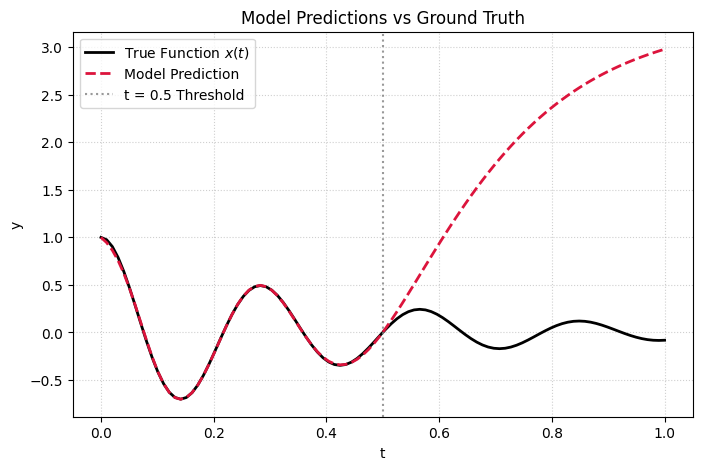

In [6]:
model.eval()

with torch.no_grad():
    t_test = torch.linspace(0, 1, 100).view(-1, 1)
    y_pred = model(t_test)
    y_true = x(t_test)

    print(t_test.shape,y_pred.shape, y_true.shape)


t_np = t_test.cpu().numpy()
y_pred_np = y_pred.cpu().numpy()
y_true_np = y_true.cpu().numpy()

# Initialize the plot
plt.figure(figsize=(8, 5))

# Plot the true values vs predictions
plt.plot(t_np, y_true_np, label='True Function $x(t)$', color='black', linewidth=2)
plt.plot(t_np, y_pred_np, label='Model Prediction', color='crimson', linestyle='--', linewidth=2)
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.8, label='t = 0.5 Threshold')

# Metadata & Styling
plt.title('Model Predictions vs Ground Truth')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


# Render
plt.show()





In [7]:
loss = criterion(y_pred, y_true)
print(f'Test Loss: {loss.item():.4f}')

Test Loss: 2.1838


## Task 2.3

In [8]:
net = Net().double()


In [9]:

# data points and collocation points
t_data = np.linspace(0, 0.5, 10)
x_data = x(t_data)
t_col = np.linspace(0, 1, 50)

lam_phys = 1e-4
lam_ic = 1

def NN(t, W1, b1, W2, b2):
    return np.sum(W2 * np.tanh(W1*t + b1)) + b2

def dNN(t, W1, b1, W2, b2):
    return np.sum(W2 * W1 * (1 - np.tanh(W1*t + b1)**2))

def ddNN(t, W1, b1, W2, b2):
    tanh = np.tanh(W1*t + b1)
    return np.sum(-2 * W2 * W1**2 * tanh * (1 - tanh**2))

def loss_terms(W1, b1, W2, b2):
  # data term
  L_data = 0
  for i in range(len(t_data)):
      L_data += (NN(t_data[i], W1, b1, W2, b2) - x_data[i])**2
  L_data = L_data / len(t_data)

  # physics term
  L_phys = 0
  for i in range(len(t_col)):
      t = t_col[i]
      r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)
      L_phys += r**2
  L_phys = L_phys / len(t_col)

  # initial conditions
  L_ic = (NN(0, W1, b1, W2, b2) - 1)**2 + (dNN(0, W1, b1, W2, b2) - 0)**2

  return L_data, L_phys, L_ic

def loss(W1, b1, W2, b2, lam_phys=lam_phys, lam_ic=lam_ic):
  L_data, L_phys, L_ic = loss_terms(W1, b1, W2, b2)
  return L_data + lam_phys*L_phys + lam_ic*L_ic





def gradients(W1, b1, W2, b2, lam_phys=lam_phys, lam_ic=lam_ic):
    dW1 = np.zeros(len(W1))
    db1 = np.zeros(len(b1))
    dW2 = np.zeros(len(W2))
    db2 = 0

    # data term
    for i in range(len(t_data)):
        t = t_data[i]
        tanh = np.tanh(W1*t + b1)
        e = NN(t, W1, b1, W2, b2) - x_data[i]

        dW1 += 2/len(t_data) * e * W2 * (1 - tanh**2) * t
        db1 += 2/len(t_data) * e * W2 * (1 - tanh**2)
        dW2 += 2/len(t_data) * e * tanh
        db2 += 2/len(t_data) * e

    # physics term
    for i in range(len(t_col)):
        t = t_col[i]
        tanh = np.tanh(W1*t + b1)
        r = ddNN(t, W1, b1, W2, b2) + mu/m * dNN(t, W1, b1, W2, b2) + k/m * NN(t, W1, b1, W2, b2)

        # eq (42)
        dr_dW1 = (-4 * W2 * W1 * tanh * (1 - tanh**2)
                  - 2 * W2 * W1**2 * t * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * t * tanh**2 * (1 - tanh**2)
                  + mu/m * (W2 * (1 - tanh**2) - 2 * W2 * W1 * t * tanh * (1 - tanh**2))
                  + k/m * W2 * t * (1 - tanh**2))

        # eq (43)
        dr_dW2 = (-2 * W1**2 * tanh * (1 - tanh**2)
                  + mu/m * W1 * (1 - tanh**2)
                  + k/m * tanh)

        # biases: same as for W1 but without the factor t from the inner derivative
        dr_db1 = (-2 * W2 * W1**2 * (1 - tanh**2)**2
                  + 4 * W2 * W1**2 * tanh**2 * (1 - tanh**2)
                  + mu/m * (-2 * W2 * W1 * tanh * (1 - tanh**2))
                  + k/m * W2 * (1 - tanh**2))
        dr_db2 = k/m

        dW1 += lam_phys * 2/len(t_col) * r * dr_dW1
        db1 += lam_phys * 2/len(t_col) * r * dr_db1
        dW2 += lam_phys * 2/len(t_col) * r * dr_dW2
        db2 += lam_phys * 2/len(t_col) * r * dr_db2

    # initial conditions (t = 0)
    tanh0 = np.tanh(b1)
    NN0 = NN(0, W1, b1, W2, b2)
    dNN0 = dNN(0, W1, b1, W2, b2)

    dW1 += lam_ic * 2 * dNN0 * W2 * (1 - tanh0**2)
    db1 += lam_ic * (2 * (NN0 - 1) * W2 * (1 - tanh0**2) - 4 * dNN0 * W2 * W1 * tanh0 * (1 - tanh0**2))
    dW2 += lam_ic * (2 * (NN0 - 1) * tanh0 + 2 * dNN0 * W1 * (1 - tanh0**2))
    db2 += lam_ic * 2 * (NN0 - 1)

    return dW1, db1, dW2, db2

## Task 2.4

In [10]:
def get_params(model):
    W1 = model.net[0].weight.detach().numpy()[:, 0]
    b1 = model.net[0].bias.detach().numpy()
    W2 = model.net[2].weight.detach().numpy()[0, :]
    b2 = model.net[2].bias.detach().numpy()[0]
    return W1, b1, W2, b2

def rel_error(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

def fd_grad_W1(W1, b1, W2, b2, lam_p=lam_phys, lam_i=lam_ic, epsilon=10 ** -5):
    dW1_fd = np.zeros(len(W1))
    for j in range(len(W1)):
        W1_minus = W1.copy()
        W1_minus[j] -= epsilon
        W1_plus = W1.copy()
        W1_plus[j] += epsilon
        dW1_fd[j] = (loss(W1_plus, b1, W2, b2, lam_p, lam_i) - loss(W1_minus, b1, W2, b2, lam_p, lam_i)) / (2*epsilon)
    return dW1_fd


torch.manual_seed(0)
net = Net().double()
W1, b1, W2, b2 = get_params(net)

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2)
dW1_fd = fd_grad_W1(W1, b1, W2, b2)

print(dW1)
print(dW1_fd)
print(" error:", rel_error(dW1, dW1_fd))

[-0.55689453 -1.33715128  0.06807861 -0.43738516  0.17951606 -0.16942355
 -1.32068953  0.56647116  0.64322223  0.39630643]
[-0.55689453 -1.33715128  0.06807861 -0.43738516  0.17951606 -0.16942355
 -1.32068953  0.56647116  0.64322223  0.39630643]
 error: 2.648413886451801e-11


## Task 2.5


In [ ]:
torch.set_default_dtype(torch.float64)

lam_ic = 1
lam_phys_list = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
optimizers = ["Adam", "LBFGS", "Adam+LBFGS"]
adam_epochs = 10000
lbfgs_iter = 2000
    
# test points on (0,1), t > 0.5 is where we have no data
t_eval = torch.linspace(0, 1, 200).view(-1, 1)
x_eval = x(t_eval)
mask_extrap = t_eval[:, 0] > 0.5


def set_grads(model, dW1, db1, dW2, db2):
    # Our parameters are converted in torch again, in order to use the optimizer
    model.net[0].weight.grad = torch.tensor(dW1).reshape(10, 1)
    model.net[0].bias.grad = torch.tensor(db1)
    model.net[2].weight.grad = torch.tensor(dW2).reshape(1, 10)
    model.net[2].bias.grad = torch.tensor([db2])


def train(lam_p, lam_i, opt_name, seed=0):
    torch.manual_seed(seed)
    model = Net().double()
    history = {"total": [], "data": [], "phys": [], "ic": []}

    # LBFGS needs a function that returns the loss, we use the same one for Adam
    def closure():
        W1, b1, W2, b2 = get_params(model)
        L_data, L_phys, L_ic = loss_terms(W1, b1, W2, b2)
        L = L_data + lam_p*L_phys + lam_i*L_ic

        history["total"].append(L)
        history["data"].append(L_data)
        history["phys"].append(L_phys)
        history["ic"].append(L_ic)

        dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2, lam_p, lam_i)
        set_grads(model, dW1, db1, dW2, db2)
        return L

    if opt_name == "Adam" or opt_name == "Adam+LBFGS":
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        for i in range(adam_epochs):
            closure()
            optimizer.step()

    if opt_name == "LBFGS" or opt_name == "Adam+LBFGS":
        optimizer = torch.optim.LBFGS(model.parameters(), lr=1, max_iter=lbfgs_iter, line_search_fn="strong_wolfe")
        optimizer.step(closure)

    with torch.no_grad():
        err = (model(t_eval) - x_eval)**2
    return model, err.mean().item(), err[mask_extrap].mean().item(), history

C:\Users\Saads\AppData\Local\Temp\ipykernel_49408\4017014904.py:22: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  return  np.exp(-1*delta*t) *(2*A(phi)* np.cos(omega*t + phi))


In [12]:
results = []
for lam_p in lam_phys_list:
    for opt_name in optimizers:
        start = time.time()
        model, mse, mse_extrap, history = train(lam_p, lam_ic, opt_name)
        run_time = time.time() - start

        results.append({"lam_p": lam_p, "opt": opt_name, "model": model, "mse": mse,
                        "mse_extrap": mse_extrap, "history": history, "time": run_time})
        print("lam_phys =", lam_p, " optimizer =", opt_name, " MSE:", mse, " MSE t>0.5:", mse_extrap, " time:", round(run_time), "s")

# best run = lowest error on t > 0.5
best = results[0]
for r in results:
    if r["mse_extrap"] < best["mse_extrap"]:
        best = r
print("Best: lam_phys =", best["lam_p"], " optimizer =", best["opt"], " MSE t>0.5:", best["mse_extrap"])

lam_phys = 1e-07  optimizer = Adam  MSE: 0.050902886713872955  MSE t>0.5: 0.09171916195935427  time: 66 s
lam_phys = 1e-07  optimizer = LBFGS  MSE: 0.02638003203051404  MSE t>0.5: 0.05244747079834662  time: 9 s
lam_phys = 1e-07  optimizer = Adam+LBFGS  MSE: 0.006147963954142272  MSE t>0.5: 0.012140340217400687  time: 78 s
lam_phys = 1e-06  optimizer = Adam  MSE: 0.014891187395708754  MSE t>0.5: 0.02722171971449971  time: 66 s
lam_phys = 1e-06  optimizer = LBFGS  MSE: 0.017638434597174096  MSE t>0.5: 0.034181533778769764  time: 20 s
lam_phys = 1e-06  optimizer = Adam+LBFGS  MSE: 0.0026635050073769285  MSE t>0.5: 0.005323488318502798  time: 83 s
lam_phys = 1e-05  optimizer = Adam  MSE: 0.010545772947963283  MSE t>0.5: 0.018698983199048166  time: 65 s
lam_phys = 1e-05  optimizer = LBFGS  MSE: 0.00851999790386474  MSE t>0.5: 0.016123166523312953  time: 14 s
lam_phys = 1e-05  optimizer = Adam+LBFGS  MSE: 0.002980786650866893  MSE t>0.5: 0.0059148110459212085  time: 70 s
lam_phys = 0.0001  o

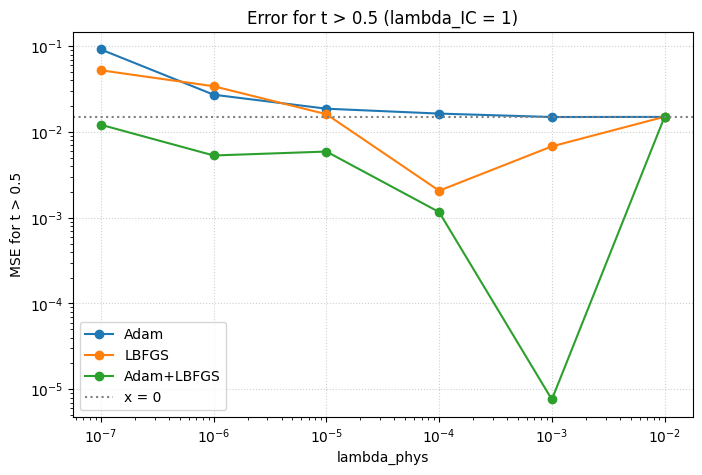

In [13]:
plt.figure(figsize=(8, 5))
for opt_name in optimizers:
    lams = []
    errs = []
    for r in results:
        if r["opt"] == opt_name:
            lams.append(r["lam_p"])
            errs.append(r["mse_extrap"])
    plt.loglog(lams, errs, 'o-', label=opt_name)

# error if the network just predicts 0
zero_err = np.mean(x_eval[mask_extrap].numpy()**2)
plt.axhline(zero_err, color='gray', linestyle=':', label='x = 0')

plt.xlabel('lambda_phys')
plt.ylabel('MSE for t > 0.5')
plt.title('Error for t > 0.5 (lambda_IC = 1)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

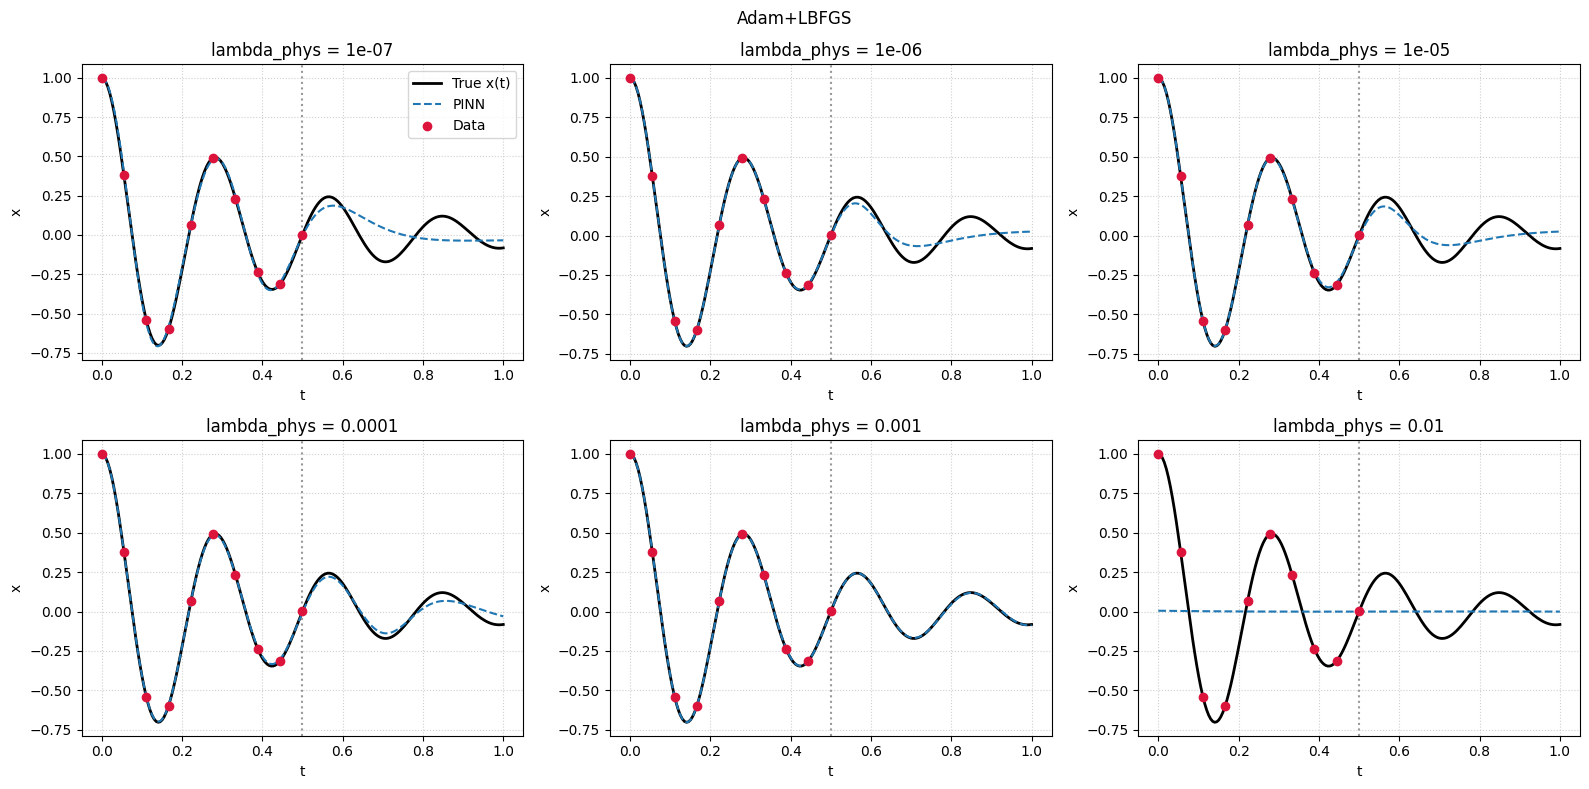

In [14]:
# weak to strong regularization with the best optimizer
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.flatten()

i = 0
for r in results:
    if r["opt"] == best["opt"]:
        with torch.no_grad():
            x_pred = r["model"](t_eval).numpy()

        ax[i].plot(t_eval.numpy(), x_eval.numpy(), label='True x(t)', color='black', linewidth=2)
        ax[i].plot(t_eval.numpy(), x_pred, '--', label='PINN')
        ax[i].scatter(t_data, x_data, color='crimson', zorder=3, label='Data')
        ax[i].axvline(x=0.5, color='gray', linestyle=':', alpha=0.8)
        ax[i].set_title('lambda_phys = ' + str(r["lam_p"]))
        ax[i].set_xlabel('t')
        ax[i].set_ylabel('x')
        ax[i].grid(True, linestyle=':', alpha=0.6)
        i += 1

ax[0].legend()
fig.suptitle(best["opt"])
plt.tight_layout()
plt.show()

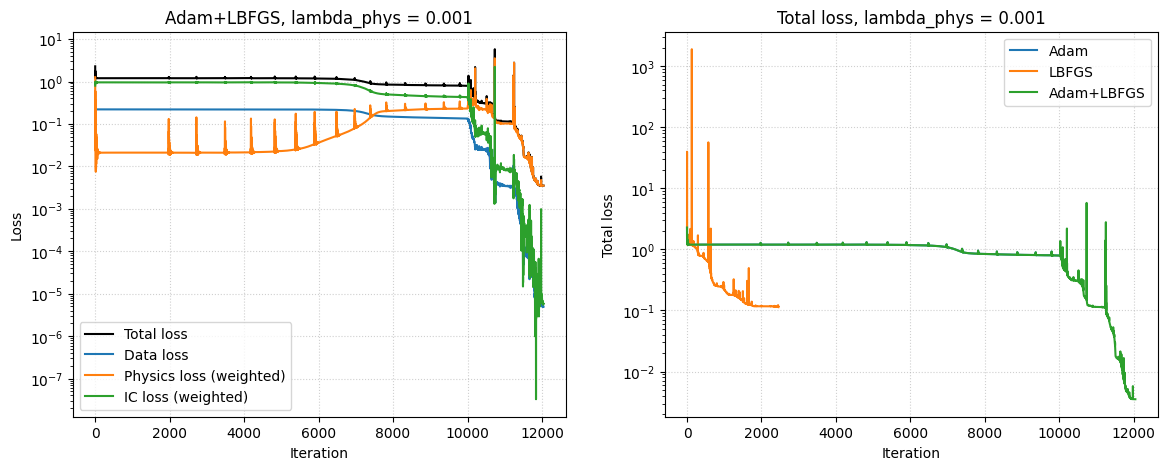

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# loss terms for the best run
h = best["history"]
ax[0].semilogy(h["total"], label='Total loss', color='black')
ax[0].semilogy(h["data"], label='Data loss')
ax[0].semilogy(best["lam_p"]*np.array(h["phys"]), label='Physics loss (weighted)')
ax[0].semilogy(lam_ic*np.array(h["ic"]), label='IC loss (weighted)')
ax[0].set_title(best["opt"] + ', lambda_phys = ' + str(best["lam_p"]))
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, linestyle=':', alpha=0.6)

# the three optimizers with the best lambda_phys
for r in results:
    if r["lam_p"] == best["lam_p"]:
        ax[1].semilogy(r["history"]["total"], label=r["opt"])
ax[1].set_title('Total loss, lambda_phys = ' + str(best["lam_p"]))
ax[1].set_xlabel('Iteration')
ax[1].set_ylabel('Total loss')
ax[1].legend()
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.show()

## Task 2.6

In [16]:
# best setting from 2.5
lam_p = best["lam_p"]
lam_i = lam_ic
opt_name = best["opt"]

t_data_t = torch.tensor(t_data).view(-1, 1)
x_data_t = torch.tensor(x_data).view(-1, 1)
t_col_t = torch.tensor(t_col).view(-1, 1).requires_grad_(True)
t0 = torch.zeros(1, 1, requires_grad=True)

def torch_loss(model, lam_p, lam_i):
    L_data = torch.mean((model(t_data_t) - x_data_t)**2)

    # x' and x'' wrt t at the collocation points
    x_col = model(t_col_t)
    dx = torch.autograd.grad(x_col, t_col_t, torch.ones_like(x_col), create_graph=True)[0]
    ddx = torch.autograd.grad(dx, t_col_t, torch.ones_like(dx), create_graph=True)[0]
    L_phys = torch.mean((ddx + mu/m * dx + k/m * x_col)**2)

    x0 = model(t0)
    dx0 = torch.autograd.grad(x0, t0, torch.ones_like(x0), create_graph=True)[0]
    L_ic = (x0 - 1)**2 + dx0**2

    return L_data + lam_p*L_phys + lam_i*L_ic[0, 0]


# gradients at initialization
torch.manual_seed(0)
net_auto = Net().double()
W1, b1, W2, b2 = get_params(net_auto)

dW1, db1, dW2, db2 = gradients(W1, b1, W2, b2, lam_p, lam_i)

L = torch_loss(net_auto, lam_p, lam_i)
grads = torch.autograd.grad(L, net_auto.parameters())

dW1_auto = grads[0].detach().numpy()[:, 0]
db1_auto = grads[1].detach().numpy()
dW2_auto = grads[2].detach().numpy()[0, :]
db2_auto = grads[3].detach().numpy()[0]

print("loss hand:", loss(W1, b1, W2, b2, lam_p, lam_i), " loss autograd:", L.item())
print("W1 rel error:", rel_error(dW1, dW1_auto))
print("b1 rel error:", rel_error(db1, db1_auto))
print("W2 rel error:", rel_error(dW2, dW2_auto))
print("b2 rel error:", rel_error(db2, db2_auto))

g_hand = np.concatenate([dW1, db1, dW2, [db2]])
g_auto = np.concatenate([dW1_auto, db1_auto, dW2_auto, [db2_auto]])
print("total rel error:", rel_error(g_hand, g_auto))

# finite differences for W1 as well
dW1_fd = fd_grad_W1(W1, b1, W2, b2, lam_p, lam_i)
print("W1 hand vs FD:", rel_error(dW1, dW1_fd))
print("W1 autograd vs FD:", rel_error(dW1_auto, dW1_fd))

loss hand: 2.2804821137188123  loss autograd: 2.2804821137188123
W1 rel error: 3.9926641226597587e-16
b1 rel error: 2.1956995523001376e-16
W2 rel error: 2.448816145857695e-16
b2 rel error: 4.4199879868575473e-16
total rel error: 3.3304640124501594e-16
W1 hand vs FD: 5.011477922895755e-11
W1 autograd vs FD: 5.0114779626232e-11


time hand: 73.8040280342102 s, time autograd: 27.42087197303772 s
iterations hand: 12043  autograd: 12417
final loss hand: 0.0035260356820133116  autograd: 0.0016404605186865822
MSE hand: 6.4408770212744395e-06  autograd: 4.3232448383031766e-06
max loss diff: 5.565444711896905
max prediction diff: 0.0051685346167458235


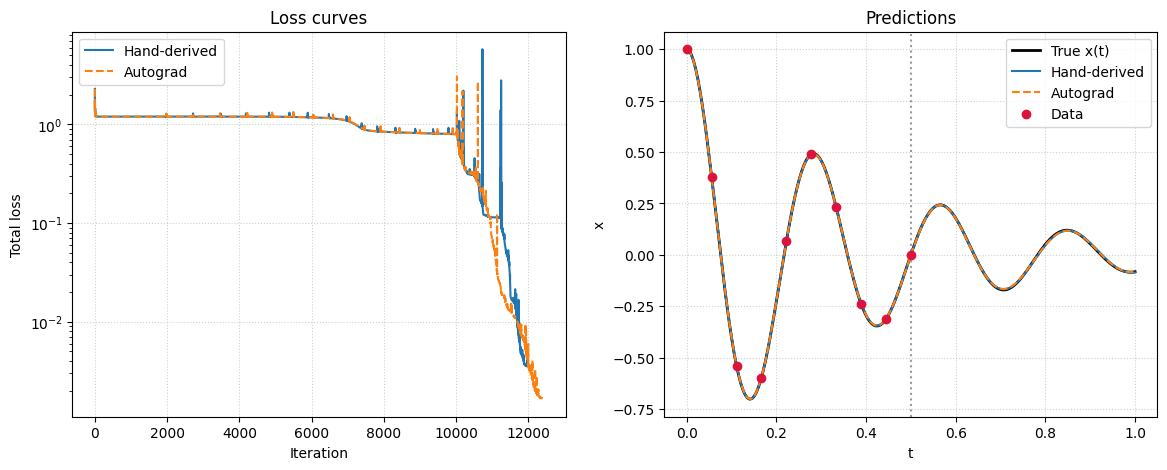

In [17]:
def train_auto(lam_p, lam_i, opt_name, seed=0):
    torch.manual_seed(seed)
    model = Net().double()
    losses = []

    # same as train() but with autograd
    def closure():
        L = torch_loss(model, lam_p, lam_i)
        grads = torch.autograd.grad(L, model.parameters())
        model.net[0].weight.grad = grads[0]
        model.net[0].bias.grad = grads[1]
        model.net[2].weight.grad = grads[2]
        model.net[2].bias.grad = grads[3]
        losses.append(L.item())
        return L.item()

    if opt_name == "Adam" or opt_name == "Adam+LBFGS":
        optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        for i in range(adam_epochs):
            closure()
            optimizer.step()

    if opt_name == "LBFGS" or opt_name == "Adam+LBFGS":
        optimizer = torch.optim.LBFGS(model.parameters(), lr=1, max_iter=lbfgs_iter, line_search_fn="strong_wolfe")
        optimizer.step(closure)

    return model, losses


# the hand-derived run is the best one from 2.5
model_hand = best["model"]
losses_hand = best["history"]["total"]
time_hand = best["time"]

start = time.time()
model_auto, losses_auto = train_auto(lam_p, lam_i, opt_name)
time_auto = time.time() - start

with torch.no_grad():
    x_hand = model_hand(t_eval).numpy()
    x_auto = model_auto(t_eval).numpy()
mse_auto = np.mean((x_auto - x_eval.numpy())**2)

n = min(len(losses_hand), len(losses_auto))
print("time hand:", time_hand, "s, time autograd:", time_auto, "s")
print("iterations hand:", len(losses_hand), " autograd:", len(losses_auto))
print("final loss hand:", losses_hand[-1], " autograd:", losses_auto[-1])
print("MSE hand:", best["mse"], " autograd:", mse_auto)
print("max loss diff:", np.max(np.abs(np.array(losses_hand[:n]) - np.array(losses_auto[:n]))))
print("max prediction diff:", np.max(np.abs(x_hand - x_auto)))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].semilogy(losses_hand, label='Hand-derived')
ax[0].semilogy(losses_auto, '--', label='Autograd')
ax[0].set_xlabel('Iteration')
ax[0].set_ylabel('Total loss')
ax[0].set_title('Loss curves')
ax[0].legend()
ax[0].grid(True, linestyle=':', alpha=0.6)

ax[1].plot(t_eval.numpy(), x_eval.numpy(), label='True x(t)', color='black', linewidth=2)
ax[1].plot(t_eval.numpy(), x_hand, label='Hand-derived')
ax[1].plot(t_eval.numpy(), x_auto, '--', label='Autograd')
ax[1].scatter(t_data, x_data, color='crimson', zorder=3, label='Data')
ax[1].axvline(x=0.5, color='gray', linestyle=':', alpha=0.8)
ax[1].set_xlabel('t')
ax[1].set_ylabel('x')
ax[1].set_title('Predictions')
ax[1].legend()
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.show()